<a href="https://colab.research.google.com/github/adibansal06/UCS420_CC_LabAssignments_1024170054/blob/main/Assignment7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420: Cognitive Computing — Assignment 7 (NLP-I)
**Name:** Aditya Bansal  
**Roll Number:** 1024170054



In [1]:
ROLL_NO = 1024170054
NAME = "Aditya Bansal"

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [3]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [4]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170054   Name: Aditya Bansal   Fingerprint: 3EF5FDC0   Tickets: 16

Ticket_ID                                                                                Ticket_Text
      T01           Server was working yesterday after the latest update. Is there another solution?
      T02                I reinstalled the LMS when I use mobile hotspot. I don't know what changed.
      T03                                                              The LMS says 'Not Submitted'.
      T04            Password keeps asking for login after resetting my password. Please resolve it.
      T05               Python keeps asking for login when I use mobile hotspot. Can you check this?
      T06                                Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it.
      T07                                           The LMS is showing an error. Can you check this?
      T08 I am unable to use the password before the assignment deadline. I don't know what changed.
      

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:
# Q1. Preprocessing pipeline

processed = [process_ticket(text) for text in df["Ticket_Text"]]

rows = []
for ticket_id, result in zip(df["Ticket_ID"], processed):
    rows.append({
        "Ticket_ID": ticket_id,
        "Sentences": len(result["sentences"]),
        "Tokens": len(result["tokens"]),
        "Punctuation Tokens": len(result["punct"]),
        "Stopwords": len(result["stops"]),
        "Unique Tokens": len(set(result["tokens"])),
        "Final Tokens": len(result["final"])
    })

summary = pd.DataFrame(rows)
total_row = {
    "Ticket_ID": "TOTAL",
    "Sentences": summary["Sentences"].sum(),
    "Tokens": summary["Tokens"].sum(),
    "Punctuation Tokens": summary["Punctuation Tokens"].sum(),
    "Stopwords": summary["Stopwords"].sum(),
    "Unique Tokens": summary["Unique Tokens"].sum(),
    "Final Tokens": summary["Final Tokens"].sum()
}
summary = pd.concat([summary, pd.DataFrame([total_row])], ignore_index=True)
display(summary)

focus_id = FOCUS[0]
focus_index = df.index[df["Ticket_ID"] == focus_id][0]
focus_result = processed[focus_index]
print("Selected ticket:", focus_id)
print(df.loc[focus_index, "Ticket_Text"])
print("\\nActual tokens:", focus_result["tokens"])
print("Punctuation tokens:", focus_result["punct"])
print("Stopwords:", focus_result["stops"])
print("Final tokens:", focus_result["final"])

print("\\nFinal tokens that may not be complete words:")
print(sorted({t for result in processed for t in result["final"]
              if t in {"n't", "'s", "ca", "'re", "'ve", "'ll", "wo", "sha", "d"} or "'" in t}))

,Ticket_ID,Sentences,Tokens,Punctuation Tokens,Stopwords,Unique Tokens,Final Tokens
0,T01,2,14,2,5,14,7
1,T02,2,17,2,7,14,8
2,T03,1,7,2,1,7,4
3,T04,2,14,2,4,12,8
4,T05,2,16,2,6,16,8
5,T06,1,9,2,2,9,5
6,T07,2,12,2,6,12,4
7,T08,2,19,2,9,16,8
8,T09,2,10,2,3,9,5
9,T10,2,12,2,5,12,5


Selected ticket: T10
The laptop keeps asking for login. Can you check this?
\nActual tokens: ['the', 'laptop', 'keeps', 'asking', 'for', 'login', '.', 'can', 'you', 'check', 'this', '?']
Punctuation tokens: ['.', '?']
Stopwords: ['the', 'for', 'can', 'you', 'this']
Final tokens: ['laptop', 'keeps', 'asking', 'login', 'check']
\nFinal tokens that may not be complete words:
["'not", "n't"]


**Answer:** Some final tokens such as `n't`, `'s`, `ca`, `wo` or `sha` may appear because `word_tokenize()` splits contractions into separate pieces. The preprocessing function removes stopwords and punctuation, but these contraction fragments are not always listed as stopwords, so they can remain in the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Q2. Regular expressions
import re

raw_texts = df["Ticket_Text"].tolist()
all_raw_text = "\n".join(raw_texts)

patterns = {
    "Words longer than 5 letters": r"\b[A-Za-z]{6,}\b",
    "Numbers": r"\b\d+(?:[.,]\d+)*(?:%?)\b",
    "Capitalized words": r"\b[A-Z][a-zA-Z]*\b",
    "Words beginning with a vowel": r"\b[aeiouAEIOU][A-Za-z]*\b"
}

print("REGEX EXTRACTION FROM RAW TICKETS")
for label, pattern in patterns.items():
    print(f"\n{label}:")
    print(re.findall(pattern, all_raw_text))

email_pattern = r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b"
url_pattern = r"\b(?:https?://|www\.)[^\s<>]+"
phone_pattern = r"(?<!\w)(?:\+\d{1,3}[\s-]?)?(?:\d[\s-]?){7,14}\d(?!\w)"

def replace_contact_details(text):
    text = re.sub(url_pattern, lambda m: m.group(0).rstrip(".,;!?") + "", text)
    # Replace URLs before emails and phone numbers to avoid matching URL digits.
    text = re.sub(email_pattern, "<EMAIL>", text)
    text = re.sub(phone_pattern, "<PHONE>", text)
    # Remove punctuation that was attached to a URL before replacement.
    text = re.sub(r"(https?://|www\.)[^\s<>]*", "<URL>", text)
    return text

print("\nREPLACEMENT ON TEST_LINES")
for line in TEST_LINES:
    replaced = re.sub(url_pattern, "<URL>", line)
    replaced = re.sub(email_pattern, "<EMAIL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)
    print(replaced)

print("\nREPLACEMENT ON RAW TICKETS")
for ticket_id, line in zip(df["Ticket_ID"], raw_texts):
    replaced = re.sub(url_pattern, "<URL>", line)
    replaced = re.sub(email_pattern, "<EMAIL>", replaced)
    replaced = re.sub(phone_pattern, "<PHONE>", replaced)
    print(ticket_id + ":", replaced)

REGEX EXTRACTION FROM RAW TICKETS

Words longer than 5 letters:
['Server', 'working', 'yesterday', 'latest', 'update', 'another', 'solution', 'reinstalled', 'mobile', 'hotspot', 'changed', 'Submitted', 'Password', 'asking', 'resetting', 'password', 'Please', 'resolve', 'Python', 'asking', 'mobile', 'hotspot', 'helpdesk', 'thapar', 'thapar', 'showing', 'unable', 'password', 'before', 'assignment', 'deadline', 'changed', 'running', 'slowly', 'worked', 'yesterday', 'laptop', 'asking', 'Laptop', 'showing', 'resetting', 'password', 'problem', 'occurs', 'uploaded', 'portal', 'opening', 'unable', 'MATLAB', 'uploading', 'problem', 'occurs', 'cannot', 'access', 'password', 'yesterday', 'Please', 'resolve', 'cannot', 'access', 'printer', 'resetting', 'password', 'another', 'computer']

Numbers:
['95.5']

Capitalized words:
['Server', 'Is', 'I', 'LMS', 'I', 'I', 'The', 'LMS', 'Not', 'Submitted', 'Password', 'Please', 'Python', 'I', 'Can', 'Write', 'The', 'LMS', 'Can', 'I', 'I', 'The', 'Wi', 'Fi',

**Answer:** Capitalized-word extraction also captures words that are capitalized only because they begin a sentence. The exact count depends on the generated tickets. The next cell calculates a simple count of capitalized matches that occur at the beginning of a sentence; proper nouns and acronyms may also be capitalized for other reasons.

## Q3. Custom tokenizer
The custom tokenizer uses one regular-expression pattern and keeps URLs, email addresses, phone numbers, versions, decimals, contractions and hyphenated words together.

In [8]:
# Q3. Custom tokenization
from nltk.tokenize import RegexpTokenizer

token_pattern = (
    r"""https?://[^\s<>]+|www\.[^\s<>]+|"""
    r"""[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"""
    r"""(?:\+\d{1,3}[\s-]?)?(?:\d[\s-]?){7,14}\d|"""
    r"""\d+(?:\.\d+)+%?|\d+(?:,\d{3})+(?:\.\d+)?%?|"""
    r"""[A-Za-z]+(?:['’][A-Za-z]+)+|"""
    r"""[A-Za-z]+(?:-[A-Za-z]+)+|"""
    r"""[A-Za-z]+|"""
    r"""[^\w\s]"""
)
custom_tokenizer = RegexpTokenizer(token_pattern)

def my_tokenize(text):
    return custom_tokenizer.tokenize(text)

print("CUSTOM TOKENIZER ON TEST_LINES")
for line in TEST_LINES:
    print("\\nText:", line)
    print("my_tokenize:", my_tokenize(line))
    print("word_tokenize:", word_tokenize(line))

print("\\nCUSTOM TOKENIZER ON TICKETS")
comparison_rows = []
for ticket_id, text in zip(df["Ticket_ID"], raw_texts):
    custom = my_tokenize(text)
    standard = word_tokenize(text)
    comparison_rows.append({
        "Ticket_ID": ticket_id,
        "Custom Tokens": custom,
        "word_tokenize Tokens": standard,
        "Different": custom != standard
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df[["Ticket_ID", "Different"]])
print("Tickets with different tokenization:",
      int(comparison_df["Different"].sum()), "out of", len(comparison_df))

print("\\nThree common differences:")
print("1. The custom tokenizer keeps contractions such as isn't together; word_tokenize may split them.")
print("2. The custom tokenizer keeps hyphenated forms such as state-of-the-art together.")
print("3. The custom tokenizer keeps URLs, email addresses, phone numbers and version numbers as single tokens.")

CUSTOM TOKENIZER ON TEST_LINES
\nText: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
my_tokenize: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
\nText: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
my_tokenize: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5%', 'done', ';', 'fee', 'Rs', '1,250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
\nText: The state-of-the-art lab isn't open; log-in at 5.30 p.

,Ticket_ID,Different
0,T01,False
1,T02,True
2,T03,True
3,T04,False
4,T05,False
5,T06,True
6,T07,False
7,T08,True
8,T09,False
9,T10,False


Tickets with different tokenization: 8 out of 16
\nThree common differences:
1. The custom tokenizer keeps contractions such as isn't together; word_tokenize may split them.
2. The custom tokenizer keeps hyphenated forms such as state-of-the-art together.
3. The custom tokenizer keeps URLs, email addresses, phone numbers and version numbers as single tokens.


**Answer:** The exact number is printed by the comparison cell. Differences occur because the custom regular expression deliberately keeps selected multi-part items (such as contractions, hyphenated words, URLs, email addresses, phone numbers and versions) together, while `word_tokenize()` follows its own tokenization rules.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [9]:
# Q4. Stemming and lemmatization
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()

unique_final_tokens = sorted({token for result in processed for token in result["final"]})

def wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged_words = pos_tag(unique_final_tokens)
pos_by_word = {word: tag for word, tag in tagged_words}

# The dataset contains forms such as "disconnecting", "uploading" and "restarting".
# The suffix "ing" is therefore selected as a simple dataset-motivated rule.
regexp_stemmer = RegexpStemmer("ing$", min=4)

stem_rows = []
for word in unique_final_tokens:
    pos = wordnet_pos(pos_by_word.get(word, "NN"))
    outputs = {
        "Word": word,
        "Porter": porter.stem(word),
        "Lancaster": lancaster.stem(word),
        "Regexp": regexp_stemmer.stem(word),
        "POS Lemma": lemmatizer.lemmatize(word, pos=pos)
    }
    if len({outputs[k] for k in ["Porter", "Lancaster", "Regexp", "POS Lemma"]}) > 1:
        stem_rows.append(outputs)

stem_table = pd.DataFrame(stem_rows)
display(stem_table)

print("Regexp suffix choice: 'ing$' was chosen because the assignment's ticket templates include words such as disconnecting, uploading and restarting when those forms occur in this generated dataset.")

,Word,Porter,Lancaster,Regexp,POS Lemma
0,another,anoth,anoth,another,another
1,assignment,assign,assign,assignment,assignment
2,changed,chang,chang,changed,change
3,computer,comput,comput,computer,computer
4,deadline,deadlin,deadlin,deadline,deadline
5,error,error,er,error,error
6,file,file,fil,file,file
7,keeps,keep,keep,keeps,keep
8,latest,latest,latest,latest,late
9,lms,lm,lms,lms,lm


Regexp suffix choice: 'ing$' was chosen because the assignment's ticket templates include words such as disconnecting, uploading and restarting when those forms occur in this generated dataset.


**Answer:** Over-stemming happens when a stemmer removes too much and produces a form that is not a meaningful word or combines words with different meanings. Under-stemming happens when related forms are not reduced to the same stem. Use the displayed comparison table to identify one actual example from this roll-number-specific dataset.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Total Tokens,Unique Tokens,TTR
S1: All tokens,208.0,87.0,0.4183
S2: Without punctuation,177.0,82.0,0.4633
S3: Final tokens,95.0,56.0,0.5895
S4: Porter-stemmed S3,95.0,53.0,0.5579


Top 10 words in S1:


,Word,Frequency
0,.,23
1,the,16
2,i,9
3,is,6
4,password,6
5,?,5
6,can,5
7,after,4
8,use,4
9,it,4


Top 10 words in S3:


,Word,Frequency
0,password,6
1,use,4
2,yesterday,3
3,lms,3
4,n't,3
5,keeps,3
6,asking,3
7,login,3
8,resetting,3
9,check,3


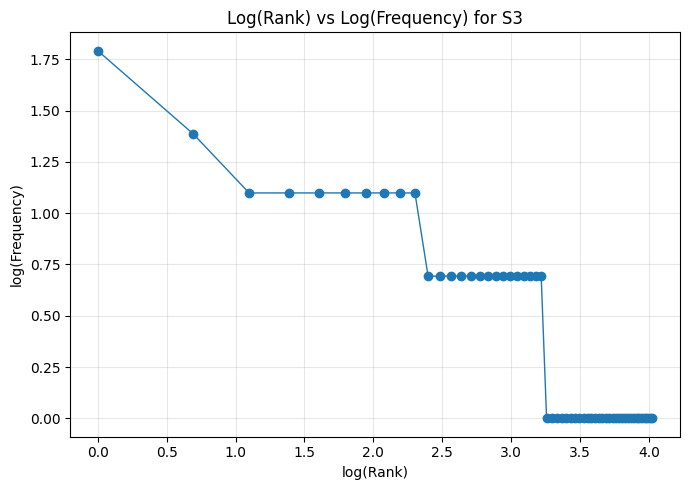

Top 5 bigrams in S1:


,Bigram,Frequency
0,"(., the)",7
1,"(., i)",4
2,"(?, i)",3
3,"(the, lms)",3
4,"(keeps, asking)",3


Top 5 bigrams in S3:


,Bigram,Frequency
0,"(keeps, asking)",3
1,"(asking, login)",3
2,"(resetting, password)",3
3,"(use, mobile)",2
4,"(mobile, hotspot)",2


TTR explanation: TTR is unique tokens divided by total tokens. Removing punctuation and stopwords changes both counts; stemming can merge several different word forms into the same stem, usually reducing the number of unique types and therefore changing TTR.


In [10]:
# Q5. Corpus statistics
from collections import Counter
from nltk.util import ngrams
import numpy as np
import matplotlib.pyplot as plt

S1 = [token for result in processed for token in result["tokens"]]
S2 = [token for token in S1 if not is_punct(token)]
S3 = [token for result in processed for token in result["final"]]
S4 = [porter.stem(token) for token in S3]

def corpus_stats(tokens):
    return {
        "Total Tokens": len(tokens),
        "Unique Tokens": len(set(tokens)),
        "TTR": round(len(set(tokens)) / len(tokens), 4) if tokens else 0
    }

stats_table = pd.DataFrame({
    "S1: All tokens": corpus_stats(S1),
    "S2: Without punctuation": corpus_stats(S2),
    "S3: Final tokens": corpus_stats(S3),
    "S4: Porter-stemmed S3": corpus_stats(S4)
}).T
display(stats_table)

print("Top 10 words in S1:")
display(pd.DataFrame(Counter(S1).most_common(10), columns=["Word", "Frequency"]))

print("Top 10 words in S3:")
display(pd.DataFrame(Counter(S3).most_common(10), columns=["Word", "Frequency"]))

freq = Counter(S3)
ranked = sorted(freq.values(), reverse=True)
ranks = np.arange(1, len(ranked) + 1)
plt.figure(figsize=(7, 5))
plt.plot(np.log(ranks), np.log(ranked), marker="o", linewidth=1)
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Top 5 bigrams in S1:")
display(pd.DataFrame(Counter(ngrams(S1, 2)).most_common(5),
                     columns=["Bigram", "Frequency"]))

print("Top 5 bigrams in S3:")
display(pd.DataFrame(Counter(ngrams(S3, 2)).most_common(5),
                     columns=["Bigram", "Frequency"]))

print("TTR explanation: TTR is unique tokens divided by total tokens. Removing punctuation and stopwords changes both counts; stemming can merge several different word forms into the same stem, usually reducing the number of unique types and therefore changing TTR.")

**Answer:** TTR is the ratio of unique tokens to total tokens. From S1 to S4, punctuation and stopword removal change the token population, while Porter stemming can merge related forms such as different inflections into one stem. The exact direction and size of the change depend on this dataset's repeated words and word forms.

---
## Q6. Interpretation

**(a) Why does TTR change from S1 to S4?**  
TTR is the number of unique tokens divided by the total number of tokens. Removing punctuation and stopwords changes the token set, and Porter stemming may combine multiple word forms into one stem. The actual change depends on the words generated for this roll number.

**(b) Give one example where `word_tokenize()` and your tokenizer differ.**  
For example, the custom tokenizer is designed to keep `state-of-the-art` as one token, whereas `word_tokenize()` may split it at hyphens. This happens because the custom regular expression explicitly recognizes hyphenated words.

**(c) Give one example where stemming produces an undesirable result.**  
A stemmer may reduce a word to a fragment that is not a valid word or may merge words with different meanings. Use the actual stemming comparison table above to select an example from this dataset.

**(d) Give one example where POS-aware lemmatization preserves meaning better than stemming.**  
For example, the verb `was` can be lemmatized to `be` when its verb part of speech is supplied. Stemming may instead return a truncated form that does not preserve the dictionary form. The exact result is shown in the comparison table.
